# Sales Prediction Using Advertising Spend

**Task:** DS5  
**Data provenance:** ISLR Advertising dataset (200 observations; TV, radio, newspaper, sales).

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
path = DATA_DIR / "Advertising.csv"

if not path.exists():
        raise FileNotFoundError(f"Download ISLR Advertising.csv; expected {path}.")

print("DATA PROVENANCE: ISLR Advertising teaching dataset; observational relationships do not prove causal effects.")

df = pd.read_csv(path).rename(columns=lambda name: name.strip().title())

df = df.rename(columns={"Tv": "TV"})

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

report(df)

DATA PROVENANCE: ISLR Advertising teaching dataset; observational relationships do not prove causal effects.
Shape: (200, 4)

Dtypes:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Nulls:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Descriptive statistics:
            count      mean        std  min     25%     50%      75%    max
TV         200.0  147.0425  85.854236  0.7  74.375  149.75  218.825  296.4
Radio      200.0   23.2640  14.846809  0.0   9.975   22.90   36.525   49.6
Newspaper  200.0   30.5540  21.778621  0.3  12.750   25.75   45.100  114.0
Sales      200.0   14.0225   5.217457  1.6  10.375   12.90   17.400   27.0


## Visualizations
Charts below are also saved as PNG files under `outputs/`. Read each finding before interpreting subsequent figures.

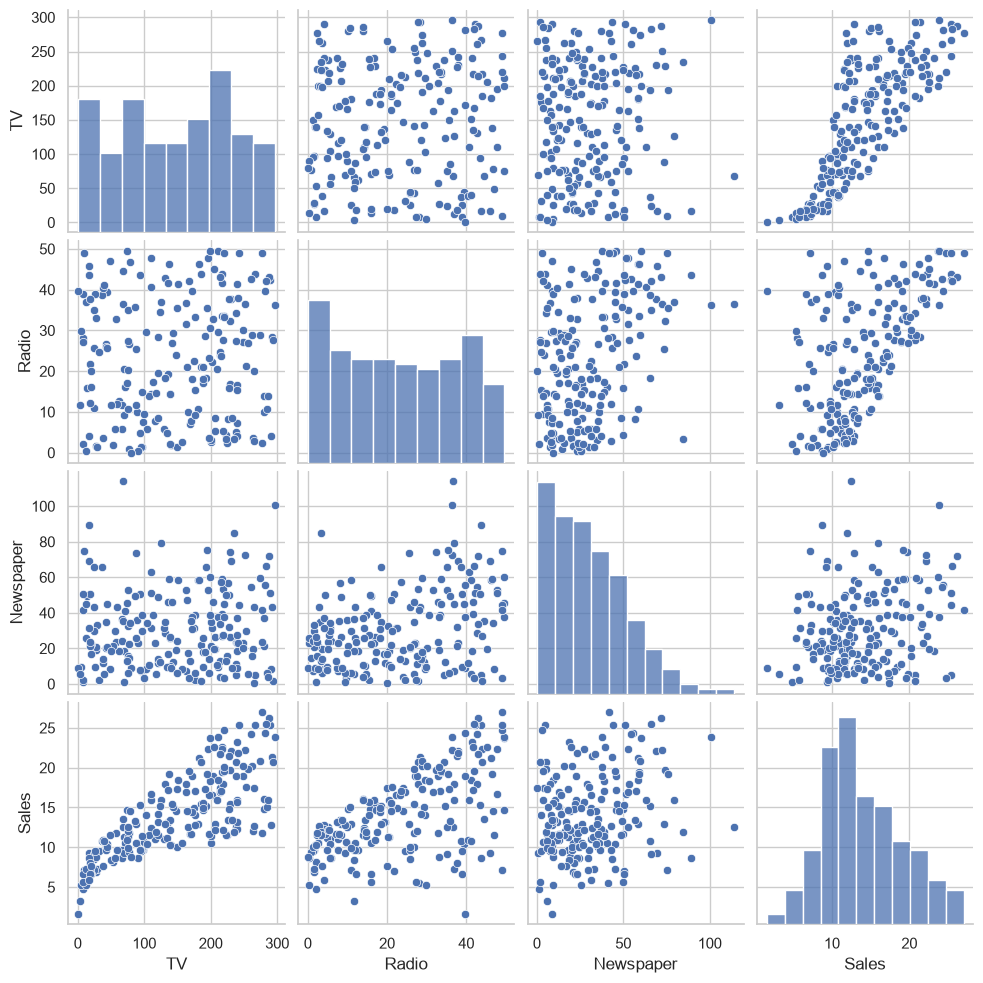

In [3]:
sns.pairplot(df)

plt.show()

### Chart 1 interpretation
The pairwise plots reveal scale and association patterns across spend channels and sales; observational correlation does not establish incremental advertising lift.

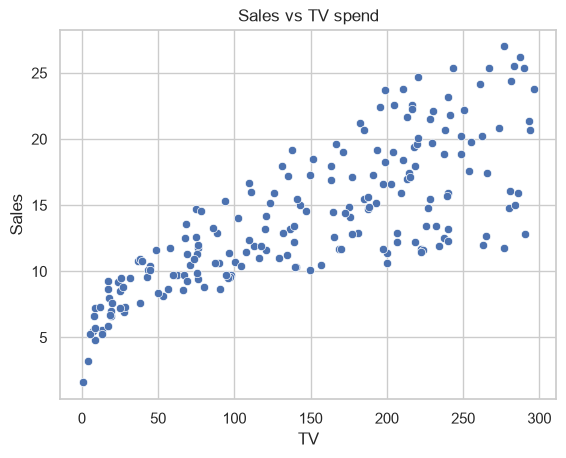

In [4]:
sns.scatterplot(data=df, x="TV", y="Sales")
plt.title("Sales vs TV spend")
plt.show()

### Chart 2 interpretation
TV spend versus sales is a useful first diagnostic, but the fitted relationship can reflect omitted factors and should not be treated as causal.

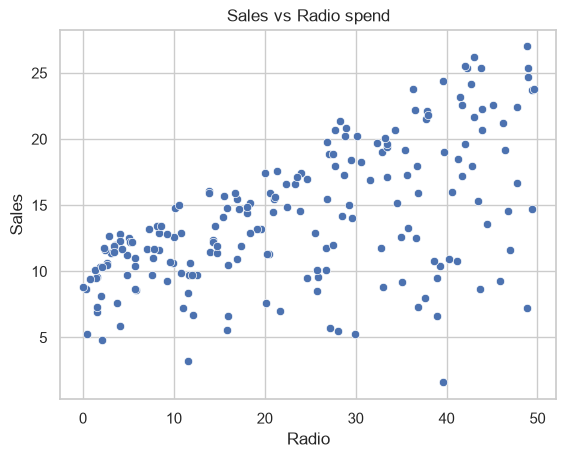

In [5]:
sns.scatterplot(data=df, x="Radio", y="Sales")
plt.title("Sales vs Radio spend")
plt.show()

### Chart 3 interpretation
Radio spend versus sales shows association in this sample; compare channel scales and validate with controlled experiments before reallocating budget.

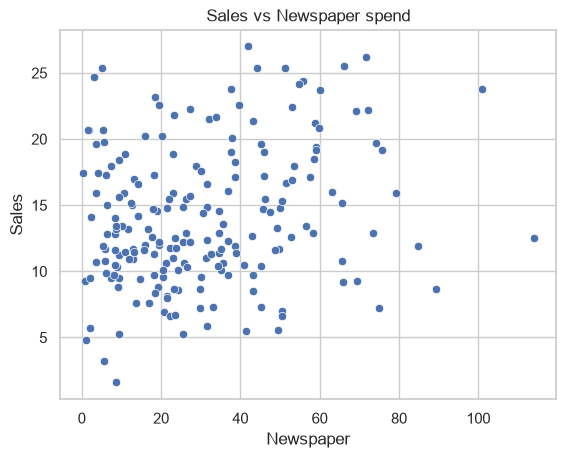

In [6]:
sns.scatterplot(data=df, x="Newspaper", y="Sales")
plt.title("Sales vs Newspaper spend")
plt.show()

### Chart 4 interpretation
Newspaper spend versus sales may be weaker or noisier than other channels; coefficient interpretation depends on the other spend variables.

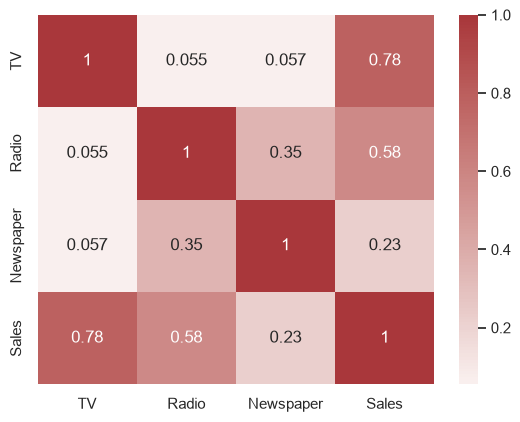

In [7]:
sns.heatmap(df.corr(), annot=True, cmap="vlag", center=0)

plt.show()

### Chart 5 interpretation
The correlation matrix summarizes linear associations among spend channels and sales; correlated predictors can make individual regression coefficients unstable, and none of these associations proves causal lift.

## Model Training / Analysis
Fit and compare appropriate models, or perform the task-specific analytical transformation where supervised model training does not apply.

Linear Regression: MAE=1.461, RMSE=1.782, R²=0.899
Random Forest: MAE=0.662, RMSE=0.821, R²=0.979


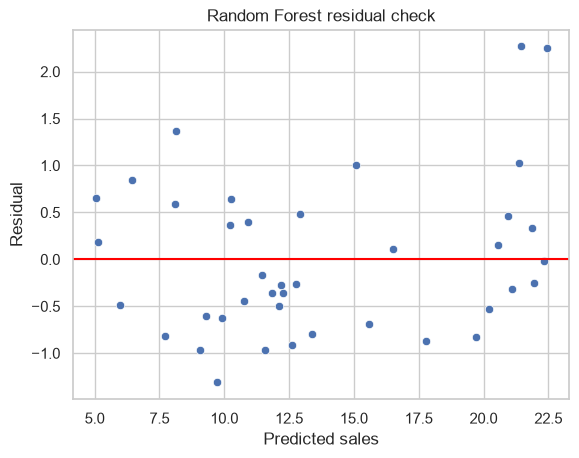

In [8]:
x_train, x_test, y_train, y_test = train_test_split(df.drop(columns="Sales"), df.Sales, test_size=.2, random_state=SEED)

results = [
        score_regressor("Linear Regression", LinearRegression(), x_train, x_test, y_train, y_test),
        score_regressor("Random Forest", RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=SEED), x_train, x_test, y_train, y_test),
    ]

best = max(results, key=lambda row: row["r2"])

residuals = y_test-best["prediction"]

sns.scatterplot(x=best["prediction"], y=residuals)

plt.axhline(0, color="red")

plt.title(f"{best['name']} residual check")

plt.xlabel("Predicted sales")

plt.ylabel("Residual")

plt.show()

### Chart 6 interpretation
The residual plot checks whether prediction errors are centered near zero and whether their spread changes with predicted sales. Patterns or widening spread indicate model limits that should temper budget decisions.

In [9]:
print("Linear coefficients:\n", pd.Series(results[0]["model"].coef_, index=x_train.columns).sort_values(ascending=False))

strongest = pd.Series(results[0]["model"].coef_, index=x_train.columns).abs().idxmax()

print(f"Largest absolute linear coefficient per spend unit: {strongest}. Compare channel scales before interpreting impact; observational data do not establish causal lift.")

Linear coefficients:
 Radio        0.189195
TV           0.044730
Newspaper    0.002761
dtype: float64
Largest absolute linear coefficient per spend unit: Radio. Compare channel scales before interpreting impact; observational data do not establish causal lift.


## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [10]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'Advertising Sales Prediction',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,model,mae,rmse,r2
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.661869,0.820503,0.978671


Saved 6 chart(s) and evaluation summary: D:\Oasis\DataScience-Task5-AdvertisingSalesPrediction\outputs\evaluation_summary.csv
